<a href="https://colab.research.google.com/github/Addreta/Subgraph-Centrality/blob/main/non_bipartite.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

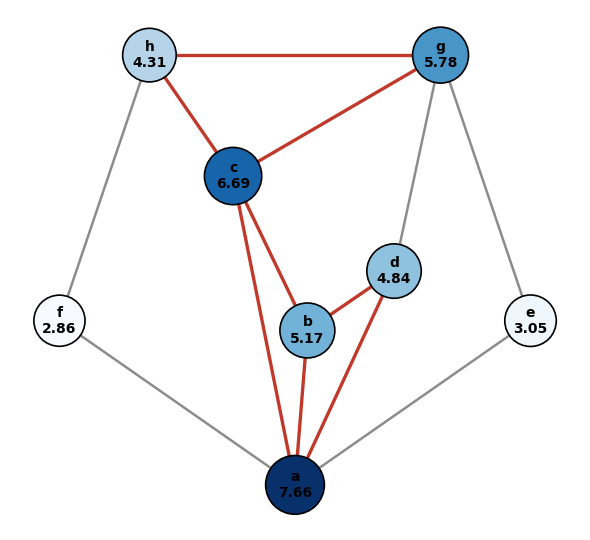

In [1]:
import numpy as np, networkx as nx, matplotlib.pyplot as plt
from scipy.linalg import expm

edges = [('a','b'),('a','c'),('a','d'),('a','e'),('a','f'),('b','c'),('b','d'),('c','g'),('c','h'),('d','g'),('e','g'),('f','h'),('g','h')]
nodes = list("abcdefgh")
G = nx.Graph(); G.add_nodes_from(nodes); G.add_edges_from(edges)
A = nx.to_numpy_array(G, nodelist=nodes)
SC = np.diag(expm(A))                       # subgraph centrality at beta = 1

# fixed layout: outer pentagon a-f-h-g-e (a cycle of the graph), vertices c, d, b inside it
ang = {'a': 270, 'f': 198, 'h': 126, 'g': 54, 'e': 342}
pos = {v: (np.cos(np.radians(a)), np.sin(np.radians(a))) for v, a in ang.items()}
pos.update({'c': (-0.25, 0.30), 'd': (0.40, -0.10), 'b': (0.05, -0.35)})

# triangles: highlight the edges that lie on a triangle
tri_edges = set()
for a, b, c in (t for t in nx.enumerate_all_cliques(G) if len(t) == 3):
    tri_edges |= {frozenset(p) for p in [(a,b),(b,c),(a,c)]}
on_tri = [e for e in G.edges if frozenset(e) in tri_edges]
off_tri = [e for e in G.edges if frozenset(e) not in tri_edges]

fig, ax = plt.subplots(figsize=(6, 5.5))
nx.draw_networkx_edges(G, pos, edgelist=off_tri, width=1.8, edge_color="0.55", ax=ax)
nx.draw_networkx_edges(G, pos, edgelist=on_tri, width=2.4, edge_color="#c0392b", ax=ax)
nx.draw_networkx_nodes(G, pos, nodelist=nodes, node_size=1100 + 90 * SC, node_color=SC, cmap="Blues",
                       edgecolors="black", linewidths=1.2, ax=ax)
nx.draw_networkx_labels(G, pos, labels={v: f"{v}\n{SC[i]:.2f}" for i, v in enumerate(nodes)}, font_size=10, font_weight="bold", ax=ax)
#ax.set_title("Non-bipartite benchmark graph (8 vertices, 13 edges, 3 triangles)\n"
             #"vertex label: name and SC(v) at β = 1;  red edges lie on a triangle", fontsize=10)
ax.axis("off"); fig.tight_layout()
fig.savefig("graph_X.png", dpi=200)
plt.show()

In [2]:
#this cell defines our non-bipartite graph and determines its degrees/ranks using subgraph centrality, sc, calculated using networkx (nx.subgraph_centrality).
# we use it later to validate our exact SC (calculated using numpy)

import networkx as nx

# Define the graph (vertices a-h)
G = nx.Graph([
    ('a', 'b'), ('a', 'c'), ('a', 'd'), ('a', 'e'), ('a', 'f'),
    ('b', 'c'), ('b', 'd'),
    ('c', 'g'), ('c', 'h'),
    ('d', 'g'),
    ('e', 'g'),
    ('f', 'h'),
    ('g', 'h'),
])

print("bipartite?", nx.is_bipartite(G))                       # added: should be False (it has odd cycles)
print("triangles :", sum(nx.triangles(G).values()) // 3)      # added: should be 3

# Subgraph centrality
sc = nx.subgraph_centrality(G)

print("\nSubgraph centrality:")
for node in sorted(sc):
    print(f"{node}: {sc[node]:.6f}")

# Normalized subgraph centrality
# only added to guard against overflow for large lambda. Not used anywhere else in the pipeline
sc_norm = nx.subgraph_centrality(G, normalized=True)

print("\nNormalized subgraph centrality:")
for node in sorted(sc_norm):
    print(f"{node}: {sc_norm[node]:.6f}")

# Degree of each node
print("\nDegrees:")
for node in sorted(G.nodes()):
    print(f"{node}: {G.degree(node)}")

bipartite? False
triangles : 3

Subgraph centrality:
a: 7.664244
b: 5.165987
c: 6.687861
d: 4.839192
e: 3.045803
f: 2.855561
g: 5.778268
h: 4.313197

Normalized subgraph centrality:
a: 0.239670
b: 0.161546
c: 0.209137
d: 0.151327
e: 0.095246
f: 0.089297
g: 0.180693
h: 0.134879

Degrees:
a: 5
b: 3
c: 4
d: 3
e: 2
f: 2
g: 4
h: 3


In [3]:
#this cell is for calculating SC using numpy. we use these SC values throughout the project
# for a non-bipartite graph SC = cosh part + sinh part, so both parts are also computed here
import networkx as nx
import numpy as np
from scipy.linalg import expm

G = nx.Graph([
    ('a', 'b'), ('a', 'c'), ('a', 'd'), ('a', 'e'), ('a', 'f'),
    ('b', 'c'), ('b', 'd'),
    ('c', 'g'), ('c', 'h'),
    ('d', 'g'),
    ('e', 'g'),
    ('f', 'h'),
    ('g', 'h'),
])

nodes = sorted(G.nodes())
A = nx.to_numpy_array(G, nodelist=nodes, weight=None)

beta = 1.0
E = expm(beta * A)
SC_exact = dict(zip(nodes, np.diag(E)))

for n in nodes:
    print(f"{n}: {SC_exact[n]:.6f}")

sc_nx = nx.subgraph_centrality(G)
print("max |difference| vs networkx:", max(abs(sc_nx[n]-SC_exact[n]) for n in nodes))

# added: the even (cosh) and odd (sinh) parts. Unlike the bipartite graph, the sinh part is not zero.
w, V = np.linalg.eigh(A)
cosh_part = np.diag((V * np.cosh(beta * w)) @ V.T)
sinh_part = np.diag((V * np.sinh(beta * w)) @ V.T)
print("\n  node   SC        cosh part  sinh part  sinh/SC")
for i, n in enumerate(nodes):
    print(f"  {n}   {SC_exact[n]:9.6f} {cosh_part[i]:9.6f} {sinh_part[i]:9.6f}  {sinh_part[i]/SC_exact[n]:.3f}")
print("max |cosh + sinh - SC|:", np.max(np.abs(cosh_part + sinh_part - np.diag(E))))


a: 7.664244
b: 5.165987
c: 6.687861
d: 4.839192
e: 3.045803
f: 2.855561
g: 5.778268
h: 4.313197
max |difference| vs networkx: 1.13509202037676e-12

  node   SC        cosh part  sinh part  sinh/SC
  a    7.664244  6.105459  1.558784  0.203
  b    5.165987  3.820919  1.345068  0.260
  c    6.687861  5.206255  1.481606  0.222
  d    4.839192  4.031255  0.807937  0.167
  e    3.045803  2.867537  0.178265  0.059
  f    2.855561  2.682250  0.173311  0.061
  g    5.778268  4.872588  0.905680  0.157
  h    4.313197  3.542011  0.771187  0.179
max |cosh + sinh - SC|: 1.13509202037676e-12


In [4]:
#this cell normalizes the adjacency matrix and builds the Chebyshev polynomials for BOTH branches:
# even branch: cosh(z x)/cosh(z)   (closed walks of even length)
# odd  branch: sinh(z x)/sinh(z)   (closed walks of odd length; this part was zero for the bipartite graph)
import numpy as np
from scipy.special import ive
from numpy.polynomial import chebyshev as C

# ---------- normalize the adjacency matrix ----------
beta = 1.0
lam = np.max(np.abs(np.linalg.eigvalsh(A)))                    # spectral norm of A
alpha = 1.001 * max(lam, np.sqrt(np.max(np.abs(A @ A).sum(axis=1))))   # also covers PennyLane's BlockEncode rule
z = beta * alpha
print(f"spectral norm = {lam:.6f}   alpha = {alpha:.6f}   z = beta*alpha = {z:.6f}")
print(f"cosh(z) = {np.cosh(z):.4f}   sinh(z) = {np.sinh(z):.4f}\n")

# ---------- Chebyshev (Bessel) coefficients ----------
def cheb_coeffs(z, deg, parity):
    """weights of T_0, T_1, ..., T_deg.
    parity = 0: target cosh(zx)/cosh(z), only even degrees are non-zero
    parity = 1: target sinh(zx)/sinh(z), only odd degrees are non-zero"""
    k = np.arange(deg + 1)                         # polynomial degrees
    c = 2.0 * ive(k, z)                            # Bessel weights, scaled by e^-z because of ive
    c[0] = ive(0, z)                               # T0 has no factor 2 (it is masked out below for the odd branch)
    c[k % 2 != parity] = 0.0                       # keep only the degrees of the right parity
    if parity == 0:
        return c / (0.5 * (1 + np.exp(-2 * z)))    # divide by cosh(z), scaled by e^-z to match ive
    return c / (0.5 * (1 - np.exp(-2 * z)))        # divide by sinh(z), scaled by e^-z to match ive

def tail_error(z, deg, parity):
    """exact worst-case error = sum of the discarded weights"""
    c_full = cheb_coeffs(z, deg + 60, parity)      # same function with 60 more terms
    return float(np.sum(np.abs(c_full[deg + 1:])))

def degree_for_eps(z, eps, parity, max_deg=200):   # determining up to how many degrees to keep
    d = parity                                     # even branch starts at 0, odd branch at 1
    while tail_error(z, d, parity) > eps:
        d += 2                                     # each branch only uses its own parity
        if d > max_deg:
            raise RuntimeError("tolerance not reached; raise max_deg")
    return d, cheb_coeffs(z, d, parity)

d_e, c_e = degree_for_eps(z, 1e-3, parity=0)
d_o, c_o = degree_for_eps(z, 1e-3, parity=1)
print(f"even branch degree: {d_e}   tail error: {tail_error(z, d_e, 0):.3e}")
print(f"  weights on T0, T2, T4, ...: {np.round(c_e[::2], 6)}")
print(f"odd  branch degree: {d_o}   tail error: {tail_error(z, d_o, 1):.3e}")
print(f"  weights on T1, T3, T5, ...: {np.round(c_o[1::2], 6)}\n")

# ---------- verify admissibility ----------
def check_admissibility(c, z, parity):
    xs = np.linspace(-1, 1, 200_001)               # the grid of test points
    P = C.chebval(xs, c)                           # the polynomial at every grid point
    if parity == 0:
        target = np.cosh(z * xs) / np.cosh(z)      # the exact function at every grid point
        name, sign = "even (cosh)", 1
    else:
        target = np.sinh(z * xs) / np.sinh(z)
        name, sign = "odd (sinh)", -1

    grid_error = np.max(np.abs(P - target))
    parity_violation = np.max(np.abs(C.chebval(-xs, c) - sign * P))   # even: P(-x) = P(x); odd: P(-x) = -P(x)
    max_abs_P = np.max(np.abs(P))
    admissible = max_abs_P <= 1.0

    print(f"{name} branch:")
    print(f"  1. grid evaluation : worst-case error vs target = {grid_error:.3e}")
    print(f"  2. parity check    : max deviation = {parity_violation:.2e}  "
          f"-> {'OK' if parity_violation < 1e-9 else 'FAILED'}")
    print(f"  3. admissibility   : max|P(x)| = {max_abs_P:.10f}  "
          f"-> {'OK, no scaling needed' if admissible else 'OVERSHOOT -- needs delta scaling'}")

    c_safe, delta = c, 0.0
    if not admissible:
        delta = (1.0 - 1.0 / max_abs_P) * 1.01
        c_safe = c * (1 - delta)
        print(f"     applying delta = {delta:.2e}; divide recovered amplitude by {1-delta:.6f} later")
    return c_safe, delta

c_e_safe, delta_e = check_admissibility(c_e, z, parity=0)
c_o_safe, delta_o = check_admissibility(c_o, z, parity=1)
print(f"\nSC error bound, even part: cosh(z) * tail error = {np.cosh(z) * tail_error(z, d_e, 0):.2e}")
print(f"SC error bound, odd  part: sinh(z) * tail error = {np.sinh(z) * tail_error(z, d_o, 1):.2e}")

spectral norm = 3.465060   alpha = 3.876856   z = beta*alpha = 3.876856
cosh(z) = 24.1465   sinh(z) = 24.1258

even branch degree: 6   tail error: 6.412e-04
  weights on T0, T2, T4, ...: [0.420966 0.469003 0.099124 0.010266]
odd  branch degree: 7   tail error: 1.320e-04
  weights on T1, T3, T5, ...: [0.723515 0.2392   0.034479 0.002674]

even (cosh) branch:
  1. grid evaluation : worst-case error vs target = 6.412e-04
  2. parity check    : max deviation = 0.00e+00  -> OK
  3. admissibility   : max|P(x)| = 0.9993588465  -> OK, no scaling needed
odd (sinh) branch:
  1. grid evaluation : worst-case error vs target = 1.320e-04
  2. parity check    : max deviation = 0.00e+00  -> OK
  3. admissibility   : max|P(x)| = 0.9998680498  -> OK, no scaling needed

SC error bound, even part: cosh(z) * tail error = 1.55e-02
SC error bound, odd  part: sinh(z) * tail error = 3.18e-03


In [5]:
!pip install pennylane

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 86.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 37.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 43.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 67.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 114.6 MB/s  0:00:00
  Attempting uninstall: autograd
    Found existing installation: autograd 1.9.1
    Uninstalling autograd-1.9.1:
      Successfully uninstalled autograd-1.9.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [pennylane]


In [6]:
# this cell is blockencoding the adjacency matrix using pennylane's function
import numpy as np, pennylane as qml
from scipy.linalg import expm

beta = 1.0
lam_max = np.max(np.abs(np.linalg.eigvalsh(A)))
alpha = 1.001 * max(lam_max, np.sqrt(np.max(np.abs(A @ A).sum(axis=1))))  # 3.876856
z = beta * alpha
At = A / alpha
print("alpha =", alpha, " norm(At) =", np.linalg.norm(At, 2)) #checking to make sure the norm is less than 1

BE = qml.BlockEncode(At, wires=range(4)) # the unitary matrix is a 2^4x2^4 (4 qubits, hilbert space dim=16)
U = qml.matrix(BE)
print("U shape:", U.shape)
print("unitary error:", np.abs(U @ U.conj().T - np.eye(16)).max())
print("top-left block equals At:", np.allclose(U[:8, :8], At))


alpha = 3.876856329553624  norm(At) = 0.8937808967970242
U shape: (16, 16)
unitary error: 1.6653345369377348e-15
top-left block equals At: True


In [7]:
#this cell finds the QSVT angles for the even polynomial (degree 6) and the odd polynomial (degree 7), checks that each QSVT circuit applies its
#polynomial to Ã, then averages each circuit with its mirror to get the real part and compares the SC estimates with the exact ones.
#the even circuit estimates the cosh part, the odd circuit estimates the sinh part, and SC = cosh part + sinh part.

poly_e = C.cheb2poly(c_e)                      # monomial form needed for PennyLane
poly_o = C.cheb2poly(c_o)
angles_e = qml.poly_to_angles(poly_e, "QSVT")  # classical phase finding: solves the angles for us
angles_o = qml.poly_to_angles(poly_o, "QSVT")
print("number of angles: even", len(angles_e), "  odd", len(angles_o))      # 7 and 8

def qsvt_block(ang):
    projs = [qml.PCPhase(a, dim=8, wires=range(4)) for a in ang]  ## one phase gate (a 16x16 matrix) per angle, vertex states get e^(+ia), the other 8 get e^(-ia)
    M = qml.matrix(qml.QSVT(BE, projs), wire_order=range(4))      # QSVT(BE, projs) alternates the Ã box (BE) with the phase gates
    return M[:8, :8]                                              # we keep only the top-left 8x8 corner

w, V = np.linalg.eigh(At)
SC_ex = np.diag(expm(beta * A))                # exact SC (numpy)
CH_ex = cosh_part                              # exact cosh part (from Cell 2)
SH_ex = sinh_part                              # exact sinh part (from Cell 2)

def run_branch(name, c, angles, scale, exact_part):
    blk = qsvt_block(angles)                   # runs the qsvt circuit
    P_At = (V * C.chebval(w, c)) @ V.T         # classically calculated exact P(Ã)
    print(f"{name}:")
    print("  max |imag(block)|        :", np.abs(blk.imag).max())              # the raw circuit output is complex, so the real-part trick is needed
    print("  max |real(block) - P(Ã)| :", np.abs(blk.real - P_At).max())
    # real part: average the circuit with its mirror (negated angles)
    blk_re = (blk + qsvt_block(-np.array(angles))) / 2
    est = scale * np.diag(blk_re).real         # the circuit's estimate of this part of SC
    print("  max abs error on this part:", np.abs(est - exact_part).max())
    return est

est_e = run_branch("even (cosh) branch", c_e, angles_e, np.cosh(z), CH_ex)
est_o = run_branch("odd (sinh) branch ", c_o, angles_o, np.sinh(z), SH_ex)

sc_est = est_e + est_o
print("\nSC exact  :", np.round(SC_ex, 6))
print("SC circuit:", np.round(sc_est, 6))
print("max abs error (even + odd):", np.abs(sc_est - SC_ex).max())
print("max rel error             :", np.max(np.abs(sc_est - SC_ex) / SC_ex))
names = sorted(G.nodes())
rank = lambda x: [names[i] for i in np.argsort(-x)]   # vertex names from highest to lowest
print("ranking exact  :", rank(SC_ex))
print("ranking circuit:", rank(sc_est))
print("ranking from the even part alone:", rank(est_e))

number of angles: even 7   odd 8
even (cosh) branch:
  max |imag(block)|        : 0.4649565428396332
  max |real(block) - P(Ã)| : 2.5279778270714814e-13
  max abs error on this part: 0.010335282488113773
odd (sinh) branch :
  max |imag(block)|        : 0.43879263560940435
  max |real(block) - P(Ã)| : 1.822986206434507e-13
  max abs error on this part: 0.0020411508696537295

SC exact  : [7.664244 5.165987 6.687861 4.839192 3.045803 2.855561 5.778268 4.313197]
SC circuit: [7.666079 5.174728 6.68527  4.834553 3.040066 2.854041 5.779446 4.322194]
max abs error (even + odd): 0.008996728632570061
max rel error             : 0.002085860688369796
ranking exact  : ['a', 'c', 'g', 'b', 'd', 'h', 'e', 'f']
ranking circuit: ['a', 'c', 'g', 'b', 'd', 'h', 'e', 'f']
ranking from the even part alone: ['a', 'c', 'g', 'd', 'b', 'h', 'e', 'f']


even (cosh) branch, degree 6:
  max |response - P|      : 9.993117444651034e-13
  max |response - target| : 0.0006411534742665204
odd (sinh) branch, degree 7 :
  max |response - P|      : 1.000088900582341e-12
  max |response - target| : 0.00013195016644118596


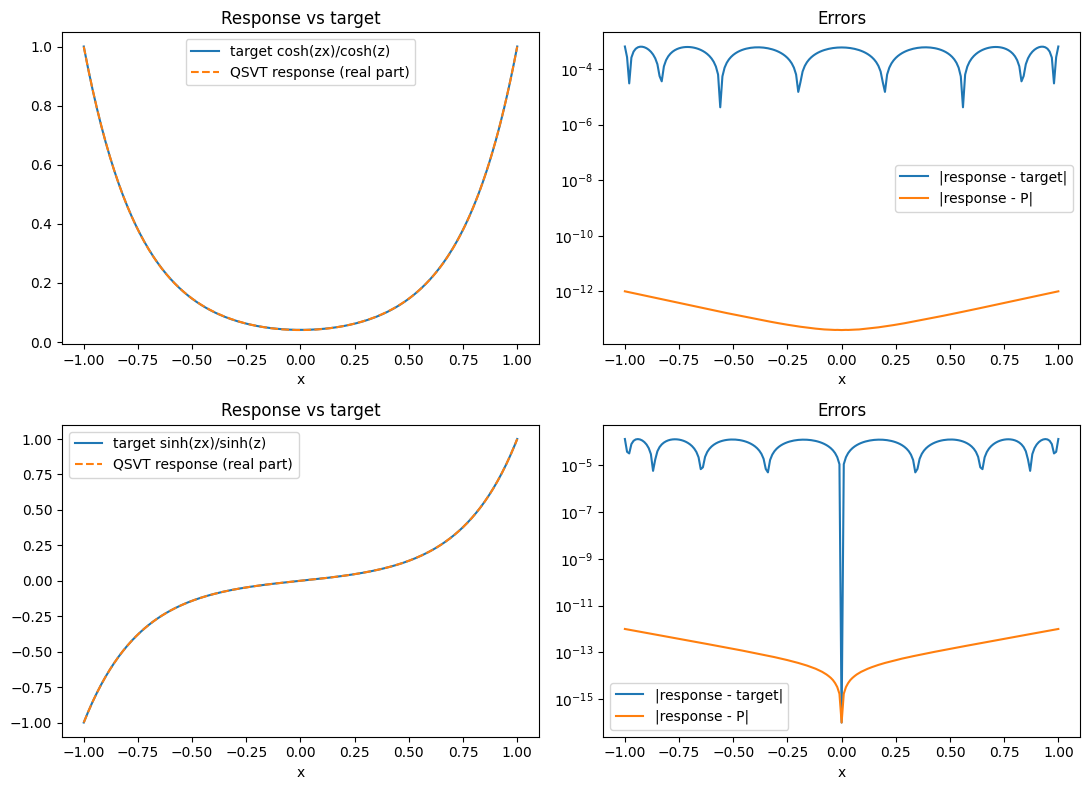

In [8]:
import matplotlib.pyplot as plt
#For this response plot only, we replace the matrix Ã with a single number x and sweep x across [−1, 1]
#done for both polynomials: the even one (cosh) and the odd one (sinh)
def response_at(x, ang):
    be = qml.BlockEncode(np.array([[x]]), wires=[0])
    projs = [qml.PCPhase(a, dim=1, wires=[0]) for a in ang]
    return qml.matrix(qml.QSVT(be, projs), wire_order=[0])[0, 0]

xs = np.linspace(-1, 1, 201)

def response_check(name, c, angles, target):
    r1 = np.array([response_at(x, angles) for x in xs])
    r2 = np.array([response_at(x, -np.array(angles)) for x in xs])
    resp = ((r1 + r2) / 2).real             # real-part average, as before
    P = C.chebval(xs, c)                    # the polynomial
    print(f"{name}:")
    print("  max |response - P|      :", np.abs(resp - P).max())        # checking if the circuit matches our polynomial almost exactly, i.e. if the angles are correct
    print("  max |response - target| :", np.abs(resp - target).max())   # the truncation error
    return resp, P

target_e = np.cosh(z * xs) / np.cosh(z)     # exact functions
target_o = np.sinh(z * xs) / np.sinh(z)
resp_e, P_e = response_check("even (cosh) branch, degree 6", c_e, angles_e, target_e)
resp_o, P_o = response_check("odd (sinh) branch, degree 7 ", c_o, angles_o, target_o)

fig, ax = plt.subplots(2, 2, figsize=(11, 8))
for row, (resp, P, target, label) in enumerate([(resp_e, P_e, target_e, "cosh(zx)/cosh(z)"),
                                                 (resp_o, P_o, target_o, "sinh(zx)/sinh(z)")]):
    ax[row, 0].plot(xs, target, label="target " + label)
    ax[row, 0].plot(xs, resp, "--", label="QSVT response (real part)")
    ax[row, 0].legend(); ax[row, 0].set_xlabel("x"); ax[row, 0].set_title("Response vs target")
    ax[row, 1].semilogy(xs, np.abs(resp - target) + 1e-16, label="|response - target|")
    ax[row, 1].semilogy(xs, np.abs(resp - P) + 1e-16, label="|response - P|")
    ax[row, 1].legend(); ax[row, 1].set_xlabel("x"); ax[row, 1].set_title("Errors")
plt.tight_layout(); plt.show()

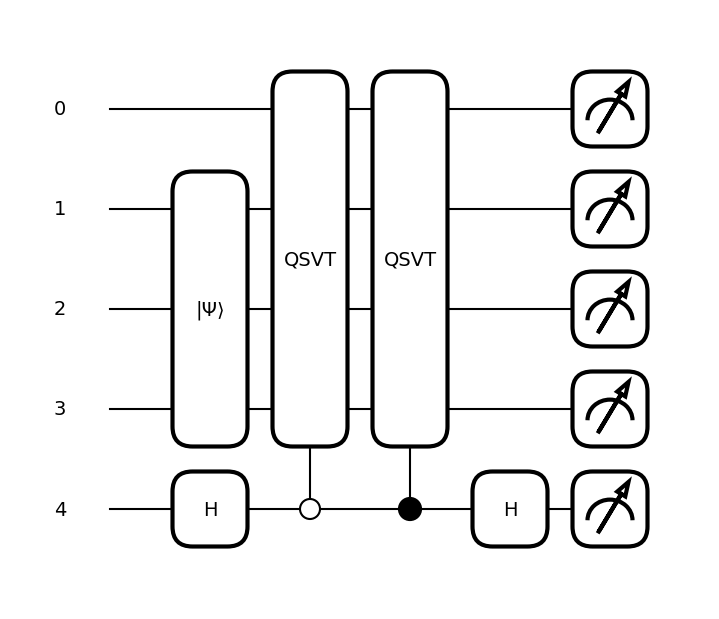

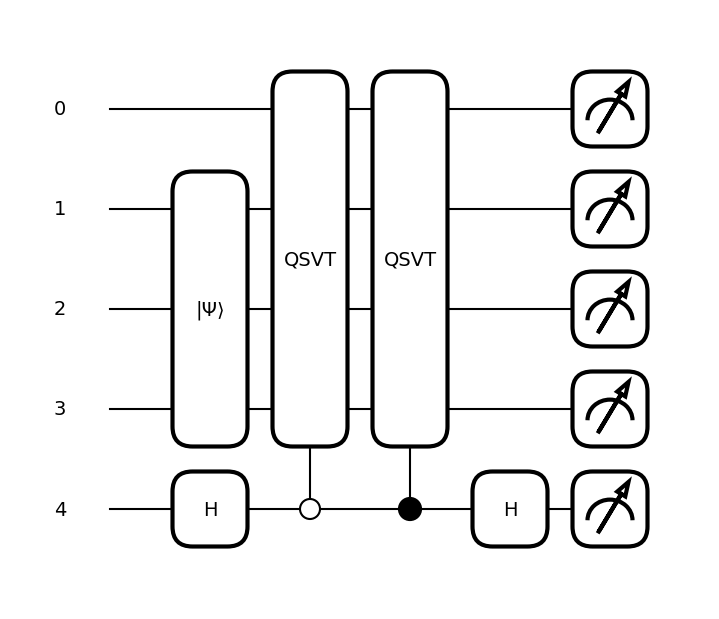

vertices             : ['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h']
p_success even       : [0.064  0.0252 0.0464 0.0278 0.0141 0.0123 0.0408 0.0216]
p_success odd        : [4.173e-03 3.106e-03 3.772e-03 1.122e-03 5.400e-05 5.000e-05 1.406e-03
 1.018e-03]
cosh(z)*sqrt(p_even) : [6.10756  3.830231 5.203558 4.026345 2.863149 2.682771 4.874893 3.552346]
cosh part exact      : [6.105459 3.820919 5.206255 4.031255 2.867537 2.68225  4.872588 3.542011]
sinh(z)*sqrt(p_odd)  : [1.558519 1.344496 1.481712 0.808208 0.176917 0.17127  0.904553 0.769848]
sinh part exact      : [1.558784 1.345068 1.481606 0.807937 0.178265 0.173311 0.90568  0.771187]
SC from the circuits : [7.666079 5.174728 6.68527  4.834553 3.040066 2.854041 5.779446 4.322194]
SC exact             : [7.664244 5.165987 6.687861 4.839192 3.045803 2.855561 5.778268 4.313197]
max abs error        : 0.008996728632572726
max |circuit - Cell 6 estimate| : 1.7763568394002505e-15


In [ ]:
#this cell builds the 5-qubit real-part circuit for BOTH branches (even: 7 angles, odd: 8 angles; drawn as circuit_5q_even.png and circuit_5q_odd.png)
#and reads the success probability for each vertex. The even circuit gives the cosh part of SC and the odd circuit gives the sinh part.
import matplotlib.pyplot as plt
N = 8
sc_exact = np.diag(expm(beta * A))

dev5 = qml.device("default.qubit", wires=5)   # a simulated quantum computer with 5 qubits. wires 0-3: block encoding, wire 4: real-part ancilla

def build_real_part_circuit(angles):
    projs_pos = [qml.PCPhase(a,  dim=N, wires=range(4)) for a in angles]   # the phase gates with the angles
    projs_neg = [qml.PCPhase(-a, dim=N, wires=range(4)) for a in angles]   # the phase gates with the negated angles

    @qml.qnode(dev5)   # makes the function a circuit
    def real_part_circuit(v):
        bits = [int(b) for b in format(v, "03b")]                 # turns the vertex number into 3 bits
        qml.BasisState(np.array(bits), wires=[1, 2, 3])           # input vertex |v>
        qml.Hadamard(wires=4)                                     # the first H on wire 4
        qml.ctrl(qml.QSVT(BE, projs_pos), control=4, control_values=[0])   # runs only if wire 4 is 0, with the angles
        qml.ctrl(qml.QSVT(BE, projs_neg), control=4, control_values=[1])   # runs only if wire 4 is 1, with the negated angles
        qml.Hadamard(wires=4)                                     # the last H on wire 4: merges the two branches, so the imaginary parts cancel
        return qml.probs(wires=range(5))                          # probability of each of the 32 outcomes of the 5 qubits
    return real_part_circuit

circ_e = build_real_part_circuit(angles_e)    # even branch (cosh part)
circ_o = build_real_part_circuit(angles_o)    # odd branch (sinh part)

for name, circ in [("even", circ_e), ("odd", circ_o)]:
    fig, ax = qml.draw_mpl(circ, style="black_white")(5)          # 5 = the vertex number
    fig.savefig(f"circuit_5q_{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

def p_success(circ, v):    # run the circuit starting at vertex v and read the one outcome that corresponds to a closed walk
    probs = circ(v)
    bits = [0] + [int(b) for b in format(v, "03b")] + [0]         # wire0=0, system=v, wire4=0
    return probs[int("".join(map(str, bits)), 2)]

p_e = np.array([p_success(circ_e, v) for v in range(N)])
p_o = np.array([p_success(circ_o, v) for v in range(N)])
est5_e = np.cosh(z) * np.sqrt(p_e)            # cosh part of SC
est5_o = np.sinh(z) * np.sqrt(p_o)            # sinh part of SC
est5 = est5_e + est5_o                        # SC = cosh part + sinh part

print("vertices             :", names)
print("p_success even       :", np.round(p_e, 4))
print("p_success odd        :", np.round(p_o, 6))
print("cosh(z)*sqrt(p_even) :", np.round(est5_e, 6))
print("cosh part exact      :", np.round(cosh_part, 6))
print("sinh(z)*sqrt(p_odd)  :", np.round(est5_o, 6))
print("sinh part exact      :", np.round(sinh_part, 6))
print("SC from the circuits :", np.round(est5, 6))
print("SC exact             :", np.round(sc_exact, 6))
print("max abs error        :", np.abs(est5 - sc_exact).max())
print("max |circuit - Cell 6 estimate| :", np.abs(est5 - sc_est).max())   # should be ~0: same polynomials, different circuit

In [ ]:
#this cell simulates finite shots for the two circuits to find how many are needed to get the vertex ranking right.
#each circuit is run n times per vertex (n = shots per circuit), so the total is 2n shots per vertex.
#repeating a circuit n times = binomial sampling with the success probability p (p_e for the even circuit, p_o for the odd one).
rng = np.random.default_rng(1)
true_order = np.argsort(-sc_exact)
print("true ranking:", [names[i] for i in true_order])
i_b, i_d = names.index("b"), names.index("d")      # the pair the odd branch fixes: b is above d (the even part alone gets it wrong)
i_e, i_f = names.index("e"), names.index("f")      # the closest pair (6.3% apart): e is above f
trials = 2000
print(f"{'shots/circuit':>13} | {'full ranking ok':>15} | {'b>d ok':>7} | {'e>f ok':>7} | {'mean abs SC err':>15}")
for n in [100, 1000, 10_000, 100_000, 1_000_000, 10_000_000]:
    counts_e = rng.binomial(n, p_e, size=(trials, N))
    counts_o = rng.binomial(n, p_o, size=(trials, N))
    est = np.cosh(z) * np.sqrt(counts_e / n) + np.sinh(z) * np.sqrt(counts_o / n)   # SC = cosh part + sinh part
    rank_ok = np.mean([np.array_equal(np.argsort(-e), true_order) for e in est])
    bd_ok = np.mean(est[:, i_b] > est[:, i_d])
    ef_ok = np.mean(est[:, i_e] > est[:, i_f])
    err = np.mean(np.abs(est - sc_exact))
    print(f"{n:>13} | {rank_ok:>15.3f} | {bd_ok:>7.3f} | {ef_ok:>7.3f} | {err:>15.4f}")

true ranking: ['a', 'c', 'g', 'b', 'd', 'h', 'e', 'f']
shots/circuit | full ranking ok |  b>d ok |  e>f ok | mean abs SC err
          100 |           0.001 |   0.498 |   0.413 |          1.4572
         1000 |           0.108 |   0.684 |   0.580 |          0.4517
        10000 |           0.693 |   0.920 |   0.769 |          0.1423
       100000 |           0.987 |   1.000 |   0.987 |          0.0431
      1000000 |           1.000 |   1.000 |   1.000 |          0.0142
     10000000 |           1.000 |   1.000 |   1.000 |          0.0060


In [ ]:
#This cell asks how much gate noise the two circuits can tolerate. It rebuilds each 5-qubit circuit gate by gate (even: 7 angles, odd: 8 angles)
#and compiles it into basic gates. Then it adds depolarizing noise after every CNOT, sweeps the error rate from 0 to 10⁻², and reports when the SC values go wrong and when the vertex ranking breaks.
#SC = cosh(z)*sqrt(p_even) + sinh(z)*sqrt(p_odd), with both probabilities taken from their own noisy circuit.
from collections import Counter
N = 8
sc_exact = np.diag(expm(beta * A))
true_order = np.argsort(-sc_exact)

def flatten(ops):          #flattening qsvt into phases and boxes
    out = []
    for o in ops:
        if type(o).__name__ == "ChangeOpBasis": out += flatten(list(o.operands))
        else: out.append(o)
    return out

def make_base_ops(angles):
    projs = [qml.PCPhase(a, dim=N, wires=range(4)) for a in angles]
    return flatten(qml.QSVT(BE, projs).decomposition())

base_ops_e = make_base_ops(angles_e)
base_ops_o = make_base_ops(angles_o)

def real_part_ops(v, base_ops):
    bits = [int(b) for b in format(v, "03b")]
    qml.BasisState(np.array(bits), wires=[1, 2, 3])
    qml.Hadamard(wires=4)
    for op in base_ops:
        if isinstance(op, qml.PCPhase):      # asks whether this piece is a phase gate, only the phase rotations are controlled
            a = op.data[0]                     # reads its angle a
            qml.ctrl(qml.PCPhase(a,  dim=N, wires=range(4)), control=4, control_values=[0])  # the phase with a if wire 4 is 0, and the phase with -a if wire 4 is 1
            qml.ctrl(qml.PCPhase(-a, dim=N, wires=range(4)), control=4, control_values=[1])
        else:                                # block encoding (or its adjoint) as an explicit unitary
            qml.QubitUnitary(qml.matrix(op, wire_order=range(4)), wires=range(4))  # no control on wire 4 here, because both branches use the same box
    qml.Hadamard(wires=4)

def p_target(probs, v):
    bits = [0] + [int(b) for b in format(v, "03b")] + [0]
    return probs[int("".join(map(str, bits)), 2)]

gate_set = {qml.CNOT, qml.RZ, qml.RY, qml.RX, qml.Rot, qml.Hadamard,
            qml.PauliX, qml.PhaseShift, qml.GlobalPhase}

# ---- ideal compiled circuits + gate counts ----
dev = qml.device("default.qubit", wires=5)
def make_compiled(base_ops):
    @qml.transforms.decompose(gate_set=gate_set)
    @qml.qnode(dev)
    def compiled(v):
        real_part_ops(v, base_ops)
        return qml.probs(wires=range(5))
    return compiled

compiled_e, compiled_o = make_compiled(base_ops_e), make_compiled(base_ops_o)
for name, comp in [("even", compiled_e), ("odd", compiled_o)]:
    tape = qml.workflow.construct_tape(comp)(0)
    ops = [o for o in tape.operations if not isinstance(o, qml.GlobalPhase)]
    print(name, Counter(o.name for o in ops))
    print(f"  total gates: {len(ops)}   CNOTs: {sum(isinstance(o, qml.CNOT) for o in ops)}")

pe_ideal = np.array([p_target(compiled_e(v), v) for v in range(N)])
po_ideal = np.array([p_target(compiled_o(v), v) for v in range(N)])
est_ideal = np.cosh(z) * np.sqrt(pe_ideal) + np.sinh(z) * np.sqrt(po_ideal)
print("ideal-compiled max SC err:", np.abs(est_ideal - sc_exact).max())

# ---- depolarizing noise on every CNOT ----  runs both compiled circuits with noise after every CNOT
dev_m = qml.device("default.mixed", wires=5)
def run_noisy(p2, base_ops):
    def cnot_noise(op, **kw):
        qml.DepolarizingChannel(p2, wires=op.wires[0])
        qml.DepolarizingChannel(p2, wires=op.wires[1])
    nm = qml.NoiseModel({qml.noise.op_eq(qml.CNOT): cnot_noise})
    @qml.add_noise(nm)
    @qml.transforms.decompose(gate_set=gate_set)
    @qml.qnode(dev_m)
    def circ(v):
        real_part_ops(v, base_ops)
        return qml.probs(wires=range(5))
    return np.array([p_target(circ(v), v) for v in range(N)])

i_b, i_d, i_e, i_f = (names.index(x) for x in "bdef")
print(f"\n{'err/CNOT-qubit':>14} | {'rank ok':>7} | {'max SC err':>10} | {'b-d gap kept':>12} | {'e-f gap kept':>12}")
for p2 in [0.0, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2]:
    pe_n, po_n = run_noisy(p2, base_ops_e), run_noisy(p2, base_ops_o)
    est = np.cosh(z) * np.sqrt(pe_n) + np.sinh(z) * np.sqrt(po_n)
    rank_ok = np.array_equal(np.argsort(-est), true_order)
    gap_bd = (est[i_b] - est[i_d]) / (est_ideal[i_b] - est_ideal[i_d])    # fraction of the ideal b-d gap that survives
    gap_ef = (est[i_e] - est[i_f]) / (est_ideal[i_e] - est_ideal[i_f])    # fraction of the ideal e-f gap that survives
    print(f"{p2:>14.0e} | {str(rank_ok):>7} | {np.abs(est - sc_exact).max():>10.3f} | {gap_bd:>12.3f} | {gap_ef:>12.3f}")

even Counter({'RZ': 1254, 'CNOT': 739, 'RY': 564, 'PhaseShift': 116, 'Hadamard': 62, 'PauliX': 14, 'RX': 3})
  total gates: 2752   CNOTs: 739
odd Counter({'RZ': 1464, 'CNOT': 863, 'RY': 660, 'PhaseShift': 134, 'Hadamard': 72, 'PauliX': 16, 'RX': 3})
  total gates: 3212   CNOTs: 863
ideal-compiled max SC err: 0.008996728632398643

err/CNOT-qubit | rank ok | max SC err | b-d gap kept | e-f gap kept
         0e+00 |    True |      0.009 |        1.000 |        1.000
         1e-04 |    True |      1.171 |        0.231 |        1.040
         3e-04 |   False |      1.920 |       -0.047 |        0.977
         1e-03 |    True |      2.899 |        0.025 |        0.542
         3e-03 |   False |      3.971 |        0.162 |       -0.008
         1e-02 |   False |      5.124 |        0.007 |       -0.003


In [ ]:
#This cell tries to fix the odd circuit's noise problem with zero-noise extrapolation: run each circuit at 1x, 2x and 3x the noise level, then extrapolate the
#success probabilities back to zero noise BEFORE taking the square root. (On real hardware the 2x and 3x runs come from gate folding; here we simply scale the error rate.)
cache = {}
def noisy_probs(p2):                            # both circuits at one error rate, each computed only once
    if p2 not in cache:
        cache[p2] = (run_noisy(p2, base_ops_e), run_noisy(p2, base_ops_o))
    return cache[p2]

def extrapolate(p2, lams):                      # polynomial (Richardson) extrapolation of p to zero noise
    L = np.array(lams, float)
    w = [np.prod([(0 - L[j]) / (L[i] - L[j]) for j in range(len(L)) if j != i]) for i in range(len(L))]   # weights for lambda -> 0
    pts = [noisy_probs(l * p2) for l in lams]
    return [sum(w[i] * pts[i][k] for i in range(len(L))) for k in (0, 1)]    # k = 0: even circuit, k = 1: odd circuit

def sc_from(pe, po):
    return np.cosh(z) * np.sqrt(np.clip(pe, 0, None)) + np.sinh(z) * np.sqrt(np.clip(po, 0, None))   # clip: extrapolation can give tiny negative values

print(f"{'err/CNOT-qubit':>14} | {'method':<20} | {'rank ok':>7} | {'max SC err':>10}")
for p2 in [1e-4, 3e-4, 1e-3]:
    for name, (pe, po) in [("no mitigation", noisy_probs(p2)),
                           ("linear (1x, 2x)", extrapolate(p2, [1, 2])),
                           ("quadratic (1x,2x,3x)", extrapolate(p2, [1, 2, 3]))]:
        est = sc_from(pe, po)
        print(f"{p2:>14.0e} | {name:<20} | {str(np.array_equal(np.argsort(-est), true_order)):>7} | {np.abs(est - sc_exact).max():>10.3f}")

err/CNOT-qubit | method               | rank ok | max SC err
         1e-04 | no mitigation        |    True |      1.171
         1e-04 | linear (1x, 2x)      |    True |      0.396
         1e-04 | quadratic (1x,2x,3x) |    True |      0.113
         3e-04 | no mitigation        |   False |      1.920
         3e-04 | linear (1x, 2x)      |    True |      1.155
         3e-04 | quadratic (1x,2x,3x) |    True |      0.742
         1e-03 | no mitigation        |    True |      2.899
         1e-03 | linear (1x, 2x)      |   False |      2.169
         1e-03 | quadratic (1x,2x,3x) |   False |      1.969


In [ ]:
#This is the full noise study for a single β (set at the top, e.g. 1.0 or 1.5). It builds the two compiled circuits (even and odd), prints their gate counts and depths, then sweeps three kinds of noise separately.
#SC = cosh(z)*sqrt(p_even) + sinh(z)*sqrt(p_odd): noise is applied to BOTH circuits and the two noisy estimates are added.
#For each noise level, it prints how far the SC values are off (MAE and the largest relative error), how well the ranking holds (Spearman and Kendall correlations), and
#whether the top vertex, the top-3 set, and the full ranking are still correct. At the end it lists, for each noise type, the first level where the values exceed 5% error,
#the ranking changes, the top-3 set fails, and the top vertex fails.
beta = 1.0          # or 1.5
QUICK = False       # True = one level per noise type, for a fast test

from scipy.stats import spearmanr, kendalltau
N = 8
names = sorted(G.nodes())
lam_max = np.max(np.abs(np.linalg.eigvalsh(A)))
alpha = 1.001 * max(lam_max, np.sqrt(np.max(np.abs(A @ A).sum(axis=1))))
At = A / alpha
BE = qml.BlockEncode(At, wires=range(4))
z = beta * alpha
sc_exact = np.diag(expm(beta * A)); true_order = np.argsort(-sc_exact)

def cheb_coeffs(z, deg, parity):
    k = np.arange(deg + 1)
    c = 2.0 * ive(k, z); c[0] = ive(0, z); c[(k % 2) != parity] = 0.0
    return c / ((0.5 * (1 + np.exp(-2 * z))) if parity == 0 else (0.5 * (1 - np.exp(-2 * z))))
def tail_error(z, deg, parity): return float(np.sum(np.abs(cheb_coeffs(z, deg + 60, parity)[deg + 1:])))
def degree_for_eps(z, eps, parity):
    d = parity
    while tail_error(z, d, parity) > eps: d += 2
    return d
def flatten(ops):
    out = []
    for o in ops:
        if type(o).__name__ == "ChangeOpBasis": out += flatten(list(o.operands))
        else: out.append(o)
    return out

abs_gap = np.min(np.diff(np.sort(sc_exact)))
deg_e = degree_for_eps(z, 0.25 * abs_gap / np.cosh(z), 0)      # tolerance: a quarter of the smallest SC gap, on the SC scale of each branch
deg_o = degree_for_eps(z, 0.25 * abs_gap / np.sinh(z), 1)
angles_e = qml.poly_to_angles(C.cheb2poly(cheb_coeffs(z, deg_e, 0)), "QSVT")
angles_o = qml.poly_to_angles(C.cheb2poly(cheb_coeffs(z, deg_o, 1)), "QSVT")
def make_base_ops(angles):
    projs = [qml.PCPhase(a, dim=N, wires=range(4)) for a in angles]
    return flatten(qml.QSVT(BE, projs).decomposition())
base_e, base_o = make_base_ops(angles_e), make_base_ops(angles_o)

def real_part_ops(v, base_ops):
    bits = [int(b) for b in format(v, "03b")]
    qml.BasisState(np.array(bits), wires=[1, 2, 3])
    qml.Hadamard(wires=4)
    for op in base_ops:
        if isinstance(op, qml.PCPhase):
            a = op.data[0]
            qml.ctrl(qml.PCPhase(a,  dim=N, wires=range(4)), control=4, control_values=[0])
            qml.ctrl(qml.PCPhase(-a, dim=N, wires=range(4)), control=4, control_values=[1])
        else:
            qml.QubitUnitary(qml.matrix(op, wire_order=range(4)), wires=range(4))
    qml.Hadamard(wires=4)

gate_set = {qml.CNOT, qml.RZ, qml.RY, qml.RX, qml.Rot, qml.Hadamard, qml.PauliX, qml.PhaseShift, qml.GlobalPhase}
ONE_Q = [qml.RZ, qml.RY, qml.RX, qml.Hadamard, qml.PauliX, qml.PhaseShift]
dev_ideal = qml.device("default.qubit", wires=5)
dev_mixed = qml.device("default.mixed", wires=5)

def make_compiled(base_ops):
    @qml.transforms.decompose(gate_set=gate_set)
    @qml.qnode(dev_ideal)
    def compiled(v):
        real_part_ops(v, base_ops); return qml.probs(wires=range(5))
    return compiled
compiled_e, compiled_o = make_compiled(base_e), make_compiled(base_o)

def circuit_depth(op_list):
    level = {}
    for o in op_list:
        d = 1 + max(level.get(w, 0) for w in o.wires)
        for w in o.wires: level[w] = d
    return max(level.values())
print(f"beta = {beta}  z = {z:.3f}  alpha = {alpha:.3f}  even degree = {deg_e} ({len(angles_e)} phases)  odd degree = {deg_o} ({len(angles_o)} phases)  qubits = 5 (3 register + 2 ancilla)")
for nm_, comp in [("even", compiled_e), ("odd ", compiled_o)]:
    tape = qml.workflow.construct_tape(comp)(0)
    ops = [o for o in tape.operations if not isinstance(o, qml.GlobalPhase)]
    n_cnot = sum(isinstance(o, qml.CNOT) for o in ops)
    print(f"compiled {nm_}: {len(ops)} gates = {n_cnot} CNOT + {len(ops) - n_cnot} single-qubit;  depth = {circuit_depth(ops)}")

def idx(v): return int("".join(map(str, [0] + [int(b) for b in format(v, "03b")] + [0])), 2)

def full_probs(model_dict, v, base_ops):
    nm = qml.NoiseModel(model_dict)
    @qml.add_noise(nm)
    @qml.transforms.decompose(gate_set=gate_set)
    @qml.qnode(dev_mixed)
    def c(vv): real_part_ops(vv, base_ops); return qml.probs(wires=range(5))
    return c(v)

def noise_dict(p2=0.0, p1=0.0):
    d = {}
    if p2 > 0:
        def f2(op, **kw):
            qml.DepolarizingChannel(p2, wires=op.wires[0]); qml.DepolarizingChannel(p2, wires=op.wires[1])
        d[qml.noise.op_eq(qml.CNOT)] = f2
    if p1 > 0:
        def f1(op, **kw): qml.DepolarizingChannel(p1, wires=op.wires[0])
        d[qml.noise.op_in(ONE_Q)] = f1
    return d

def readout(probs, r):
    M = np.array([[1 - r, r], [r, 1 - r]])
    out = probs.reshape([2] * 5)
    for ax in range(5): out = np.moveaxis(np.tensordot(M, out, axes=([1], [ax])), 0, ax)
    return out.reshape(-1)

def sc_est(pe, po):      # SC = cosh part + sinh part
    return np.cosh(z) * np.sqrt(np.clip(pe, 0, None)) + np.sinh(z) * np.sqrt(np.clip(po, 0, None))

def metrics(pe, po):
    est = sc_est(pe, po)
    err = np.abs(est - sc_exact)
    return dict(mae=err.mean(), nmae=err.mean() / sc_exact.mean(), maxrel=err.max() / sc_exact.max(), # Spearman: compares the noisy ranking with the true ranking (1 = same order, 0 = unrelated, -1 = reversed);
                                                                                                       #penalizes vertices that move far from their true position
                rho=spearmanr(est, sc_exact)[0], tau=kendalltau(est, sc_exact)[0],              #Kendall: checks all 28 vertex pairs and counts how many are in the right order vs the wrong order
                                                                                                  #(1 = every pair right; each swapped pair lowers it by 2/28)
                top1=np.argmax(est) == true_order[0],
                top3=set(np.argsort(-est)[:3]) == set(true_order[:3]),
                rank=np.array_equal(np.argsort(-est), true_order))

pe_ideal = np.array([compiled_e(v)[idx(v)] for v in range(N)])
po_ideal = np.array([compiled_o(v)[idx(v)] for v in range(N)])
base = metrics(pe_ideal, po_ideal)
print(f"ideal circuits: MAE = {base['mae']:.4f}  max rel err = {base['maxrel']*100:.2f}%  rank ok = {base['rank']}")

def table(title, label, levels, make_probs):
    print(f"\n{title}")
    print(f"{label:>10} | {'MAE':>7} {'nMAE':>6} {'maxrel':>7} | {'Spearman':>8} {'Kendall':>8} | {'top1':>5} {'top3':>5} {'rank':>5}")
    rows = []
    for lv in levels:
        m = metrics(*make_probs(lv)); rows.append((lv, m))
        print(f"{lv:>10.0e} | {m['mae']:>7.3f} {m['nmae']:>6.3f} {m['maxrel']*100:>6.1f}% | {m['rho']:>8.3f} {m['tau']:>8.3f} | "
              f"{str(m['top1']):>5} {str(m['top3']):>5} {str(m['rank']):>5}")
    return rows

if QUICK: L2, L1, LR = [1e-3], [1e-4], [1e-2]
else:
    L2 = [1e-5, 3e-5, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2]
    L1 = [1e-5, 3e-5, 1e-4, 3e-4, 1e-3, 3e-3]
    LR = [1e-3, 3e-3, 1e-2, 3e-2, 1e-1]

def noisy_pair(nd):      # run both circuits under the same noise model
    return (np.array([full_probs(nd, v, base_e)[idx(v)] for v in range(N)]),
            np.array([full_probs(nd, v, base_o)[idx(v)] for v in range(N)]))

res2 = table("A. Two-qubit (CNOT) depolarizing noise, per qubit", "p2", L2, lambda p: noisy_pair(noise_dict(p2=p)))
res1 = table("B. Single-qubit depolarizing noise after every 1q gate", "p1", L1, lambda p: noisy_pair(noise_dict(p1=p)))
full_e = {v: compiled_e(v) for v in range(N)}; full_o = {v: compiled_o(v) for v in range(N)}
resr = table("C. Readout error (bit flip on each of 5 measured qubits)", "r", LR,
             lambda r: (np.array([readout(full_e[v], r)[idx(v)] for v in range(N)]),
                        np.array([readout(full_o[v], r)[idx(v)] for v in range(N)])))

def first_fail(rows, key, bad):
    for lv, m in rows:
        if bad(m[key]): return lv
    return None
print("\nThresholds (first tested level where the criterion fails; None = never in the range tested)")
for name, rows in [("CNOT p2", res2), ("1q p1", res1), ("readout r", resr)]:
    print(f"  {name:>10}: values unreliable (max rel err > 5%): {first_fail(rows,'maxrel',lambda x: x>0.05)} | "
          f"ranking changes: {first_fail(rows,'rank',lambda x: not x)} | "
          f"top-3 set fails: {first_fail(rows,'top3',lambda x: not x)} | top-1 fails: {first_fail(rows,'top1',lambda x: not x)}")

beta = 1.0  z = 3.877  alpha = 3.877  even degree = 6 (7 phases)  odd degree = 7 (8 phases)  qubits = 5 (3 register + 2 ancilla)
compiled even: 2752 gates = 739 CNOT + 2013 single-qubit;  depth = 1743
compiled odd : 3212 gates = 863 CNOT + 2349 single-qubit;  depth = 2036
ideal circuits: MAE = 0.0044  max rel err = 0.12%  rank ok = True

A. Two-qubit (CNOT) depolarizing noise, per qubit
        p2 |     MAE   nMAE  maxrel | Spearman  Kendall |  top1  top3  rank
     1e-05 |   0.142  0.028    4.0% |    1.000    1.000 |  True  True  True
     3e-05 |   0.322  0.064    8.0% |    1.000    1.000 |  True  True  True
     1e-04 |   0.701  0.139   15.3% |    1.000    1.000 |  True  True  True
     3e-04 |   1.187  0.235   25.0% |    0.976    0.929 |  True  True False
     1e-03 |   1.570  0.311   37.8% |    1.000    1.000 |  True  True  True
     3e-03 |   2.067  0.410   51.8% |    0.976    0.929 |  True  True False
     1e-02 |   2.939  0.583   66.9% |    0.881    0.714 |  True False False

B

In [ ]:
#This is the full noise study for a single β (set at the top, e.g. 1.0 or 1.5). It builds the two compiled circuits (even and odd), prints their gate counts and depths, then sweeps three kinds of noise separately.
#SC = cosh(z)*sqrt(p_even) + sinh(z)*sqrt(p_odd): noise is applied to BOTH circuits and the two noisy estimates are added.
#For each noise level, it prints how far the SC values are off (MAE and the largest relative error), how well the ranking holds (Spearman and Kendall correlations), and
#whether the top vertex, the top-3 set, and the full ranking are still correct. At the end it lists, for each noise type, the first level where the values exceed 5% error,
#the ranking changes, the top-3 set fails, and the top vertex fails.
beta = 1.5          # or 1.5
QUICK = False       # True = one level per noise type, for a fast test

from scipy.stats import spearmanr, kendalltau
N = 8
names = sorted(G.nodes())
lam_max = np.max(np.abs(np.linalg.eigvalsh(A)))
alpha = 1.001 * max(lam_max, np.sqrt(np.max(np.abs(A @ A).sum(axis=1))))
At = A / alpha
BE = qml.BlockEncode(At, wires=range(4))
z = beta * alpha
sc_exact = np.diag(expm(beta * A)); true_order = np.argsort(-sc_exact)

def cheb_coeffs(z, deg, parity):
    k = np.arange(deg + 1)
    c = 2.0 * ive(k, z); c[0] = ive(0, z); c[(k % 2) != parity] = 0.0
    return c / ((0.5 * (1 + np.exp(-2 * z))) if parity == 0 else (0.5 * (1 - np.exp(-2 * z))))
def tail_error(z, deg, parity): return float(np.sum(np.abs(cheb_coeffs(z, deg + 60, parity)[deg + 1:])))
def degree_for_eps(z, eps, parity):
    d = parity
    while tail_error(z, d, parity) > eps: d += 2
    return d
def flatten(ops):
    out = []
    for o in ops:
        if type(o).__name__ == "ChangeOpBasis": out += flatten(list(o.operands))
        else: out.append(o)
    return out

abs_gap = np.min(np.diff(np.sort(sc_exact)))
deg_e = degree_for_eps(z, 0.25 * abs_gap / np.cosh(z), 0)      # tolerance: a quarter of the smallest SC gap, on the SC scale of each branch
deg_o = degree_for_eps(z, 0.25 * abs_gap / np.sinh(z), 1)
angles_e = qml.poly_to_angles(C.cheb2poly(cheb_coeffs(z, deg_e, 0)), "QSVT")
angles_o = qml.poly_to_angles(C.cheb2poly(cheb_coeffs(z, deg_o, 1)), "QSVT")
def make_base_ops(angles):
    projs = [qml.PCPhase(a, dim=N, wires=range(4)) for a in angles]
    return flatten(qml.QSVT(BE, projs).decomposition())
base_e, base_o = make_base_ops(angles_e), make_base_ops(angles_o)

def real_part_ops(v, base_ops):
    bits = [int(b) for b in format(v, "03b")]
    qml.BasisState(np.array(bits), wires=[1, 2, 3])
    qml.Hadamard(wires=4)
    for op in base_ops:
        if isinstance(op, qml.PCPhase):
            a = op.data[0]
            qml.ctrl(qml.PCPhase(a,  dim=N, wires=range(4)), control=4, control_values=[0])
            qml.ctrl(qml.PCPhase(-a, dim=N, wires=range(4)), control=4, control_values=[1])
        else:
            qml.QubitUnitary(qml.matrix(op, wire_order=range(4)), wires=range(4))
    qml.Hadamard(wires=4)

gate_set = {qml.CNOT, qml.RZ, qml.RY, qml.RX, qml.Rot, qml.Hadamard, qml.PauliX, qml.PhaseShift, qml.GlobalPhase}
ONE_Q = [qml.RZ, qml.RY, qml.RX, qml.Hadamard, qml.PauliX, qml.PhaseShift]
dev_ideal = qml.device("default.qubit", wires=5)
dev_mixed = qml.device("default.mixed", wires=5)

def make_compiled(base_ops):
    @qml.transforms.decompose(gate_set=gate_set)
    @qml.qnode(dev_ideal)
    def compiled(v):
        real_part_ops(v, base_ops); return qml.probs(wires=range(5))
    return compiled
compiled_e, compiled_o = make_compiled(base_e), make_compiled(base_o)

def circuit_depth(op_list):
    level = {}
    for o in op_list:
        d = 1 + max(level.get(w, 0) for w in o.wires)
        for w in o.wires: level[w] = d
    return max(level.values())
print(f"beta = {beta}  z = {z:.3f}  alpha = {alpha:.3f}  even degree = {deg_e} ({len(angles_e)} phases)  odd degree = {deg_o} ({len(angles_o)} phases)  qubits = 5 (3 register + 2 ancilla)")
for nm_, comp in [("even", compiled_e), ("odd ", compiled_o)]:
    tape = qml.workflow.construct_tape(comp)(0)
    ops = [o for o in tape.operations if not isinstance(o, qml.GlobalPhase)]
    n_cnot = sum(isinstance(o, qml.CNOT) for o in ops)
    print(f"compiled {nm_}: {len(ops)} gates = {n_cnot} CNOT + {len(ops) - n_cnot} single-qubit;  depth = {circuit_depth(ops)}")

def idx(v): return int("".join(map(str, [0] + [int(b) for b in format(v, "03b")] + [0])), 2)

def full_probs(model_dict, v, base_ops):
    nm = qml.NoiseModel(model_dict)
    @qml.add_noise(nm)
    @qml.transforms.decompose(gate_set=gate_set)
    @qml.qnode(dev_mixed)
    def c(vv): real_part_ops(vv, base_ops); return qml.probs(wires=range(5))
    return c(v)

def noise_dict(p2=0.0, p1=0.0):
    d = {}
    if p2 > 0:
        def f2(op, **kw):
            qml.DepolarizingChannel(p2, wires=op.wires[0]); qml.DepolarizingChannel(p2, wires=op.wires[1])
        d[qml.noise.op_eq(qml.CNOT)] = f2
    if p1 > 0:
        def f1(op, **kw): qml.DepolarizingChannel(p1, wires=op.wires[0])
        d[qml.noise.op_in(ONE_Q)] = f1
    return d

def readout(probs, r):
    M = np.array([[1 - r, r], [r, 1 - r]])
    out = probs.reshape([2] * 5)
    for ax in range(5): out = np.moveaxis(np.tensordot(M, out, axes=([1], [ax])), 0, ax)
    return out.reshape(-1)

def sc_est(pe, po):      # SC = cosh part + sinh part
    return np.cosh(z) * np.sqrt(np.clip(pe, 0, None)) + np.sinh(z) * np.sqrt(np.clip(po, 0, None))

def metrics(pe, po):
    est = sc_est(pe, po)
    err = np.abs(est - sc_exact)
    return dict(mae=err.mean(), nmae=err.mean() / sc_exact.mean(), maxrel=err.max() / sc_exact.max(), # Spearman: compares the noisy ranking with the true ranking (1 = same order, 0 = unrelated, -1 = reversed);
                                                                                                       #penalizes vertices that move far from their true position
                rho=spearmanr(est, sc_exact)[0], tau=kendalltau(est, sc_exact)[0],              #Kendall: checks all 28 vertex pairs and counts how many are in the right order vs the wrong order
                                                                                                  #(1 = every pair right; each swapped pair lowers it by 2/28)
                top1=np.argmax(est) == true_order[0],
                top3=set(np.argsort(-est)[:3]) == set(true_order[:3]),
                rank=np.array_equal(np.argsort(-est), true_order))

pe_ideal = np.array([compiled_e(v)[idx(v)] for v in range(N)])
po_ideal = np.array([compiled_o(v)[idx(v)] for v in range(N)])
base = metrics(pe_ideal, po_ideal)
print(f"ideal circuits: MAE = {base['mae']:.4f}  max rel err = {base['maxrel']*100:.2f}%  rank ok = {base['rank']}")

def table(title, label, levels, make_probs):
    print(f"\n{title}")
    print(f"{label:>10} | {'MAE':>7} {'nMAE':>6} {'maxrel':>7} | {'Spearman':>8} {'Kendall':>8} | {'top1':>5} {'top3':>5} {'rank':>5}")
    rows = []
    for lv in levels:
        m = metrics(*make_probs(lv)); rows.append((lv, m))
        print(f"{lv:>10.0e} | {m['mae']:>7.3f} {m['nmae']:>6.3f} {m['maxrel']*100:>6.1f}% | {m['rho']:>8.3f} {m['tau']:>8.3f} | "
              f"{str(m['top1']):>5} {str(m['top3']):>5} {str(m['rank']):>5}")
    return rows

if QUICK: L2, L1, LR = [1e-3], [1e-4], [1e-2]
else:
    L2 = [1e-5, 3e-5, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2]
    L1 = [1e-5, 3e-5, 1e-4, 3e-4, 1e-3, 3e-3]
    LR = [1e-3, 3e-3, 1e-2, 3e-2, 1e-1]

def noisy_pair(nd):      # run both circuits under the same noise model
    return (np.array([full_probs(nd, v, base_e)[idx(v)] for v in range(N)]),
            np.array([full_probs(nd, v, base_o)[idx(v)] for v in range(N)]))

res2 = table("A. Two-qubit (CNOT) depolarizing noise, per qubit", "p2", L2, lambda p: noisy_pair(noise_dict(p2=p)))
res1 = table("B. Single-qubit depolarizing noise after every 1q gate", "p1", L1, lambda p: noisy_pair(noise_dict(p1=p)))
full_e = {v: compiled_e(v) for v in range(N)}; full_o = {v: compiled_o(v) for v in range(N)}
resr = table("C. Readout error (bit flip on each of 5 measured qubits)", "r", LR,
             lambda r: (np.array([readout(full_e[v], r)[idx(v)] for v in range(N)]),
                        np.array([readout(full_o[v], r)[idx(v)] for v in range(N)])))

def first_fail(rows, key, bad):
    for lv, m in rows:
        if bad(m[key]): return lv
    return None
print("\nThresholds (first tested level where the criterion fails; None = never in the range tested)")
for name, rows in [("CNOT p2", res2), ("1q p1", res1), ("readout r", resr)]:
    print(f"  {name:>10}: values unreliable (max rel err > 5%): {first_fail(rows,'maxrel',lambda x: x>0.05)} | "
          f"ranking changes: {first_fail(rows,'rank',lambda x: not x)} | "
          f"top-3 set fails: {first_fail(rows,'top3',lambda x: not x)} | top-1 fails: {first_fail(rows,'top1',lambda x: not x)}")

beta = 1.5  z = 5.815  alpha = 3.877  even degree = 8 (9 phases)  odd degree = 7 (8 phases)  qubits = 5 (3 register + 2 ancilla)
compiled even: 3664 gates = 984 CNOT + 2680 single-qubit;  depth = 2324
compiled odd : 3212 gates = 863 CNOT + 2349 single-qubit;  depth = 2036
ideal circuits: MAE = 0.0607  max rel err = 0.30%  rank ok = True

A. Two-qubit (CNOT) depolarizing noise, per qubit
        p2 |     MAE   nMAE  maxrel | Spearman  Kendall |  top1  top3  rank
     1e-05 |   0.645  0.027    3.5% |    1.000    1.000 |  True  True  True
     3e-05 |   1.715  0.071    8.5% |    1.000    1.000 |  True  True  True
     1e-04 |   4.363  0.181   19.4% |    1.000    1.000 |  True  True  True
     3e-04 |   8.734  0.362   36.4% |    1.000    1.000 |  True  True  True
     1e-03 |  14.755  0.612   60.6% |    1.000    1.000 |  True  True  True
     3e-03 |  21.167  0.878   84.5% |    1.000    1.000 |  True  True  True
     1e-02 |  30.200  1.252  109.1% |    0.905    0.786 |  True False False

B

In [ ]:
#This cell repeats the whole calculation for five values of β (0.5, 1, 1.5, 2, 3) to find which β is the best operating point. For each β it:
#picks the smallest even degree (cosh branch) and the smallest odd degree (sinh branch) that keep the SC error of each part below a quarter of the smallest gap between vertices,
#finds the angles and runs the two ideal QSVT circuits (at the matrix level, with no gate noise),
#prints the accuracy and how many shots per circuit are needed for a 95% correct ranking.
import pandas as pd
from scipy.special import ive
from numpy.polynomial import chebyshev as C

N = 8
names = sorted(G.nodes())
lam_max = np.max(np.abs(np.linalg.eigvalsh(A)))
alpha = 1.001 * max(lam_max, np.sqrt(np.max(np.abs(A @ A).sum(axis=1))))   # fixed, depends only on A
At = A / alpha
BE = qml.BlockEncode(At, wires=range(4))
w_, V_ = np.linalg.eigh(At)

def cheb_coeffs(z, deg, parity):
    k = np.arange(deg + 1)
    c = 2.0 * ive(k, z); c[0] = ive(0, z)
    c[(k % 2) != parity] = 0.0
    return c / ((0.5 * (1 + np.exp(-2 * z))) if parity == 0 else (0.5 * (1 - np.exp(-2 * z))))

def tail_error(z, deg, parity):
    c_full = cheb_coeffs(z, deg + 60, parity)
    return float(np.sum(np.abs(c_full[deg + 1:])))

def degree_for_eps(z, eps, parity, max_deg=300):
    d = parity
    while tail_error(z, d, parity) > eps:
        d += 2
        if d > max_deg: raise RuntimeError("raise max_deg")
    return d

def qsvt_block(ang):
    projs = [qml.PCPhase(a, dim=N, wires=range(4)) for a in ang]
    return qml.matrix(qml.QSVT(BE, projs), wire_order=range(4))[:N, :N]

def min_rel_gap(sc):
    v = np.sort(sc)
    return np.min(np.diff(v) / v[1:])

rng = np.random.default_rng(7)
def shots_for_ranking(pe, po, z, true_order, target=0.95, trials=400):   # n = shots per circuit
    for n in np.unique(np.logspace(2, 10, 33).astype(np.int64)):
        ce = rng.binomial(n, pe, size=(trials, N)); co = rng.binomial(n, po, size=(trials, N))
        est = np.cosh(z) * np.sqrt(ce / n) + np.sinh(z) * np.sqrt(co / n)
        ok = np.mean([np.array_equal(np.argsort(-e), true_order) for e in est])
        if ok >= target: return int(n)
    return None

def branch(z, parity, eps):
    d = degree_for_eps(z, eps, parity)
    c = cheb_coeffs(z, d, parity)
    angles = qml.poly_to_angles(C.cheb2poly(c), "QSVT")
    blk = qsvt_block(angles)
    blk_re = (blk + qsvt_block(-np.array(angles))) / 2
    chk = np.abs(blk_re - (V_ * C.chebval(w_, c)) @ V_.T).max()
    return d, tail_error(z, d, parity), np.diag(blk_re).real ** 2, chk     # degree, poly error, p, circuit-vs-poly check

rows, rankings = [], {}
for beta in [0.5, 1.0, 1.5, 2.0, 3.0]:
    z = beta * alpha
    sc = np.diag(expm(beta * A))
    true_order = np.argsort(-sc)
    abs_gap = np.min(np.diff(np.sort(sc)))
    d_e, err_e, pe, chk_e = branch(z, 0, 0.25 * abs_gap / np.cosh(z))   # SC error of each part <= a quarter of the smallest gap
    d_o, err_o, po, chk_o = branch(z, 1, 0.25 * abs_gap / np.sinh(z))
    n_need = shots_for_ranking(pe, po, z, true_order)
    sc_circ = np.cosh(z) * np.sqrt(pe) + np.sinh(z) * np.sqrt(po)
    rows.append({
        "beta": beta,
        "z": f"{z:.2f}",
        "SC max/min": f"{sc.max()/sc.min():.2f}",
        "gap (rel)": f"{min_rel_gap(sc)*100:.2f}%",
        "gap (abs)": f"{abs_gap:.4f}",
        "deg even": d_e,
        "deg odd": d_o,
        "circuit SC error": f"{np.abs(sc_circ - sc).max():.1e}",
        "p even min": f"{pe.min():.4f}",
        "p odd min": f"{po.min():.1e}",
        "shots/circuit (95% rank)": f"{n_need:,}" if n_need else "none",
        "circuit vs poly": f"{max(chk_e, chk_o):.0e}",
    })
    rankings[beta] = " > ".join(names[i] for i in true_order)

print(f"alpha = {alpha:.6f}\n")
print(pd.DataFrame(rows).to_string(index=False))
print()
if len(set(rankings.values())) == 1:
    print("True ranking (same for every beta):", next(iter(rankings.values())))
else:
    for b, r in rankings.items(): print(f"True ranking at beta = {b}: {r}")

alpha = 3.876856

 beta     z SC max/min gap (rel) gap (abs)  deg even  deg odd circuit SC error p even min p odd min shots/circuit (95% rank) circuit vs poly
  0.5  1.94       1.44     0.67%    0.0087         6        5          2.6e-04     0.1311   1.6e-06                  562,341           5e-13
  1.0  3.88       2.68     6.25%    0.1902         6        7          9.0e-03     0.0123   5.0e-05                   56,234           3e-13
  1.5  5.82       3.78     6.99%    1.6354         8        7          1.2e-01     0.0026   1.4e-04                   56,234           2e-13
  2.0  7.75       4.25     6.69%    9.0409         8        9          6.4e-01     0.0009   2.2e-04                  100,000           1e-13
  3.0 11.63       4.42     6.39%  271.1123        12       11          1.8e+01     0.0002   1.5e-04                  177,827           7e-14

True ranking (same for every beta): a > c > g > b > d > h > e > f
